ANALIZA AUGMENTACJI

In [14]:
%pip install -q albumentations opencv-python matplotlib pandas pyyaml

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt
import albumentations as A

warnings.filterwarnings("ignore", message="Got processor for bboxes")

DS = Path("dataset_clean") if Path("dataset_clean").exists() else Path("../dataset_clean")
OUT = Path("aug_preview")
OUT.mkdir(exist_ok=True)
SEED = 42
TARGETS = {"PLASTIC": 4000, "PAPER": 3500, "CARDBOARD": 3500, "METAL": 3500} #docelowa ilosc o ile mozliwe
MAX_COPIES = 2                                                               #maksymalna ilosc kopii zdj zeby nie bylo przeuczenia

cfg = yaml.safe_load((DS / "data.yaml").read_text())
NAMES = dict(enumerate(cfg["names"])) if isinstance(cfg["names"], list) else {int(k): v for k, v in cfg["names"].items()} #numer -> nazwa
COLORS = {0: (0, 200, 0), 1: (0, 140, 255), 2: (255, 200, 0), 3: (200, 200, 200), 4: (255, 255, 255), 5: (255, 0, 200)}   #inne kolory ramek w zaleznosci od klas

BBOX = A.BboxParams(format="yolo",
                    label_fields=["classes"], #klasa przypisana do ramki - usuwana razem z nia
                    clip=True)                #ramka wystaje poza kadr -> przycinanie jej do brzegu


def plan_copies(df):
    names = sorted({c for classes in df["classes"] for c in classes})
    boxes = np.array([[classes.count(c) for c in names] for classes in df["classes"]]) #wiersz = zdjecie, kolumna = klasa, wartosc = liczba obiektow
    count = boxes.sum(axis=0)                                                          #ilosc obiektow kazdej klasy
    target = np.array([TARGETS.get(c, 0) for c in names])                              #klasy spoza targets (brak wzmacniania)
    bio = names.index("BIODEGRADABLE")
    copies = np.zeros(len(df), dtype=int)
    stuck = set() #klasy niemozliwe do podniesienia - brak zdj
    while True:
        under = [j for j in range(len(names)) if j not in stuck and count[j] < target[j]]
        if not under: #wszystkie klasy osiagnely cel
            break
        rarest = min(under, key=lambda j: count[j] / target[j])           #klasa najdalej od celu procentowo
        useful = np.where(count < target, 1, -1)                          #1 brakuje -1 juz osiagnela cel
        useful[target == 0] = 0                                           #GLASS nie pomaga
        useful[bio] = -1                                                  #biodegradable za duzo
        score = boxes @ useful                                            #obiekty potrzebne - obiekty zbedne
        ok = (boxes[:, rarest] > 0) & (copies < MAX_COPIES) & (score > 0) #jest brakujaca klasa, ma < 2 kopii, wiecej pomaga niz szkodzi
        if not ok.any():
            stuck.add(rarest)
            continue
        best = np.argmax(np.where(ok, boxes[:, rarest] * 1000 + score - copies * 10**6, -10**9))
        copies[best] += 1
        count += boxes[best]
    return copies
"""
kolejnosc najlepszego zdj:
- copies * 10**6            - najpierw zdjecia jeszcze niekopiowane zeby sie nie przeuczal
boxes[:, rarest] * 1000     - najwiecej obiektow brakujacej klasy
score                       - przy remisie mniej zbednych obiektow
-10**9                      - zdjecia ktorych nie wolno wybrac nigdy nie wygraja
duze mnozniki zeby wazniejszy warunek zawsze wygrywal
"""


rows = []
for img in sorted((DS / "train/images").iterdir()):
    label = np.loadtxt(DS / "train/labels" / f"{img.stem}.txt", ndmin=2) #ndmin=2 do tabeli nawet przy 1 ramce
    classes = [NAMES[int(c)] for c in label[:, 0]] #pierwsza kolumna = numer klasy -> nazwa
    rows.append({"image": img, "n_boxes": len(label), "classes": classes})
train_df = pd.DataFrame(rows)
train_df["strong"] = plan_copies(train_df) #ilosc kopii na zdj 0,1,2
print(f"zdjec train : {len(train_df)}")

zdjec train : 3533


Rozklad klas - zbior oryginalny i po oversamplingu

original       aug_balanced             
                liczba     %       liczba     % zmiana
classes                                               
BIODEGRADABLE    13024  55.4        13067  44.7   1.00
PLASTIC           2744  11.7         4010  13.7   1.46
METAL             2595  11.0         3510  12.0   1.35
CARDBOARD         1994   8.5         3500  12.0   1.76
PAPER             1617   6.9         3523  12.0   2.18
GLASS             1538   6.5         1654   5.7   1.08

,original,aug_balanced
max / min,8.47,7.90
max / min bez BIODEGRADABLE,1.78,2.42


kopie
0    2680
1     845
2       8
Name: zdjec, dtype: int64

zdjec : 3533 -> 4394


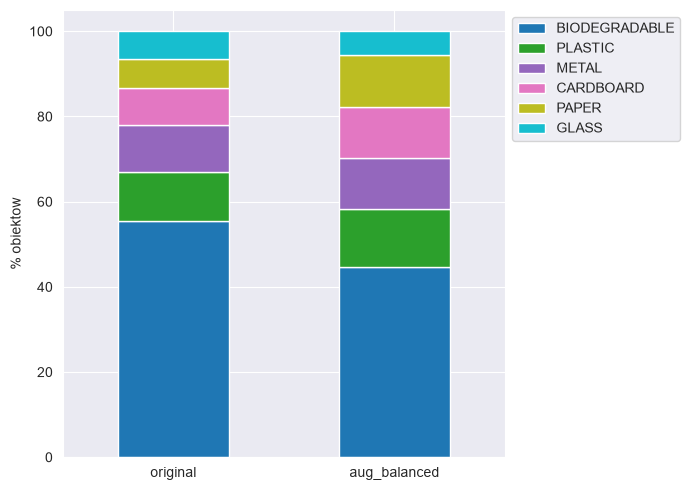

In [16]:
boxes = train_df.explode("classes") #jeden wiersz = jedna ramka
original = boxes["classes"].value_counts()
balanced = original + boxes.groupby("classes")["strong"].sum() #kazda kopia dodaje wszystkie ramki ze zdj
versions = pd.DataFrame({"original": original, "aug_balanced": balanced}).sort_values("original", ascending=False)

table = pd.concat({name: pd.DataFrame({"liczba": v, "%": (v / v.sum() * 100).round(1)})
                   for name, v in versions.items()}, axis=1)
table[("aug_balanced", "zmiana")] = (versions["aug_balanced"] / versions["original"]).round(2) #ile razy wiecej niz w oryginale
display(table)

minor = versions.drop("BIODEGRADABLE")
display(pd.DataFrame({"max / min": versions.max() / versions.min(), #ile razy najwieksza klasa wieksza od najmniejszej
                      "max / min bez BIODEGRADABLE": minor.max() / minor.min()}).round(2).T)
display(train_df["strong"].value_counts().sort_index().rename("zdjec").rename_axis("kopie"))
print(f"zdjec : {len(train_df)} -> {len(train_df) + train_df['strong'].sum()}")

(versions / versions.sum() * 100).T.plot.bar(stacked=True, figsize=(7, 5), colormap="tab10") #procenty zeby oba slupki byly tej samej wysokosci
plt.ylabel("% obiektow")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(OUT / "rozklad_klas.png", dpi=120)
plt.show()

Wizualizacja

In [17]:
def load(path):
    image = cv2.imread(str(path))
    label = np.loadtxt(DS / "train/labels" / f"{Path(path).stem}.txt", ndmin=2)
    return image, label[:, 1:], label[:, 0] #ramki x, y, w, h i klasy osobno pod albumentations


def draw(image, bboxes, classes):
    image = image.copy()
    h, w = image.shape[:2]
    for c, (x, y, bw, bh) in zip(classes, bboxes):
        color = COLORS[int(c)][::-1]             #cv2 uzywa BGR
        x1, y1, x2, y2 = (int((x - bw / 2) * w), #yolo: srodek + szerokosc w ulamkach 0,1 -> rogi w pikselach
                          int((y - bh / 2) * h),
                          int((x + bw / 2) * w),
                          int((y + bh / 2) * h))
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        cv2.putText(image, NAMES[int(c)][:4], (x1, max(y1 - 3, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)
    return image[:, :, ::-1] #z powrotem na RGB pod wykresy


def show(paths, transforms, file_name, cols_title=None):
    fig, axes = plt.subplots(len(paths), len(transforms) + 1, figsize=(4 * (len(transforms) + 1), 4 * len(paths)), squeeze=False)
    for r, path in enumerate(paths):
        image, bboxes, classes = load(path)
        axes[r, 0].imshow(draw(image, bboxes, classes))
        axes[r, 0].set_title(f"oryginal ({len(bboxes)} ramek)")
        for c, (title, t) in enumerate(transforms.items(), start=1):
            out = t(image=image, bboxes=bboxes, classes=classes) #zmienia zdjecie i ramki naraz
            axes[r, c].imshow(draw(out["image"], out["bboxes"], out["classes"]))
            axes[r, c].set_title(f"{title} ({len(out['bboxes'])} ramek)")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT / file_name, dpi=110)
    plt.show()


def pick(class_name, n=3):
    has = train_df[train_df["classes"].apply(lambda c: class_name in c)]
    return list(has.sample(min(n, len(has)), random_state=SEED)["image"]) #losowe zdj z dana klasa


def compose(*steps):
    return A.Compose(list(steps), bbox_params=BBOX, seed=SEED) #laczy kroki w jedna augmentacje, ramki przeliczane razem ze zdj


print({v: k for k, v in NAMES.items()})

{'BIODEGRADABLE': 0, 'CARDBOARD': 1, 'GLASS': 2, 'METAL': 3, 'PAPER': 4, 'PLASTIC': 5}


Zdjecia przykladowe

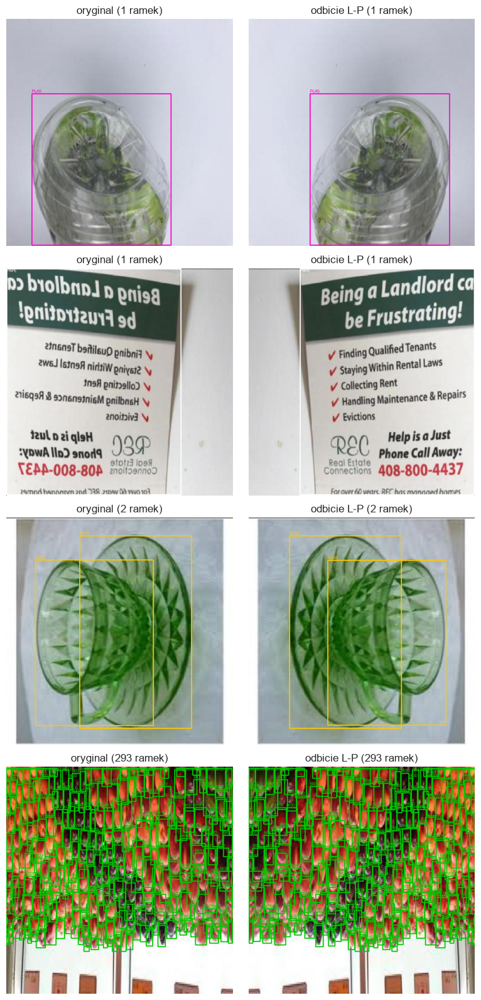

In [18]:
crowded = list(train_df.sort_values("n_boxes", ascending=False)["image"].head(1)) #zdj z najwieksza iloscia ramek
SAMPLES = pick("PLASTIC", 1) + pick("PAPER", 1) + pick("GLASS", 1) + crowded
show(SAMPLES, {"odbicie L-P": compose(A.HorizontalFlip(p=1))}, "00_oryginaly.png")

Obroty

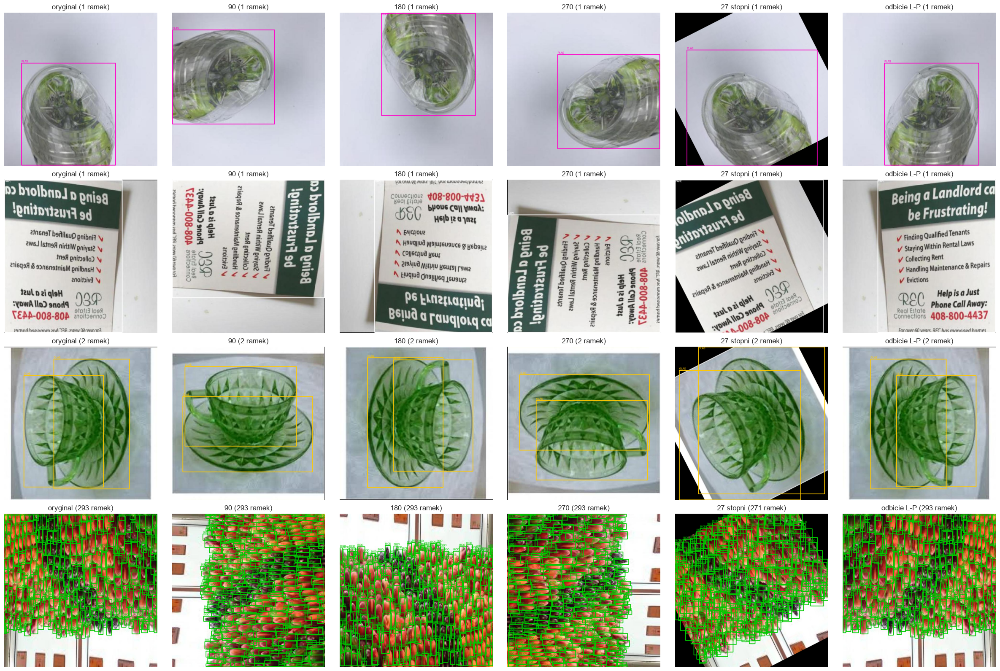

In [19]:
rotations = {
    "90": compose(A.Transpose(p=1), A.HorizontalFlip(p=1)), #obrot o pelne 90
    "180": compose(A.HorizontalFlip(p=1), A.VerticalFlip(p=1)),
    "270": compose(A.Transpose(p=1), A.VerticalFlip(p=1)),
    "27 stopni": compose(
        A.Rotate(limit=(27, 27), border_mode=cv2.BORDER_CONSTANT, p=1)), #dla porownania : czarne rogi i za duze ramki
    "odbicie L-P": compose(A.HorizontalFlip(p=1)),
}
show(SAMPLES, rotations, "01_obroty.png")

Skalowanie

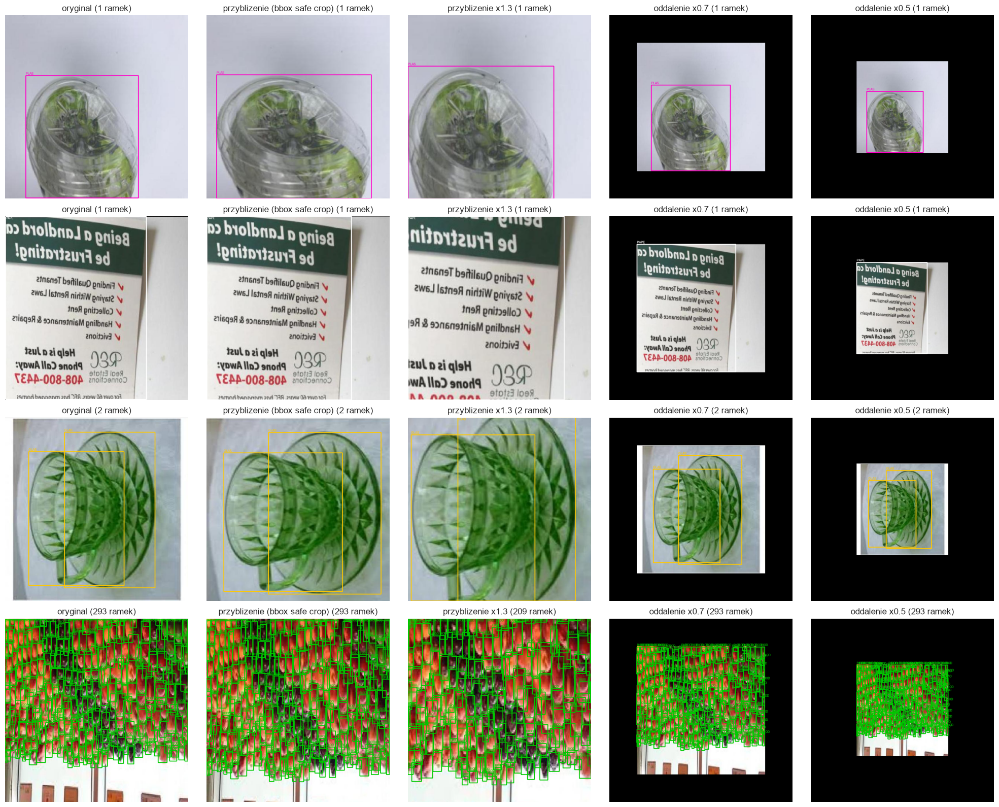

In [20]:
scales = {
    "przyblizenie (bbox safe crop)": compose(
        A.RandomSizedBBoxSafeCrop(height=640, width=640, erosion_rate=0.0, p=1)), #przyblizenie ktore nigdy nie ucina ramek
    "przyblizenie x1.3": compose(
        A.Affine(scale=(1.3, 1.3), border_mode=cv2.BORDER_CONSTANT, p=1)),        #zwykly zoom - obiekty przy brzegu wypadaja
    "oddalenie x0.7": compose(
        A.Affine(scale=(0.7, 0.7), border_mode=cv2.BORDER_CONSTANT, p=1)),        #oddalenie - male obiekty robia sie jeszcze mniejsze
    "oddalenie x0.5": compose(A.Affine(scale=(0.5, 0.5), border_mode=cv2.BORDER_CONSTANT, p=1)),
}
show(SAMPLES, scales, "02_skala.png")

Przeksztalcenia koloru

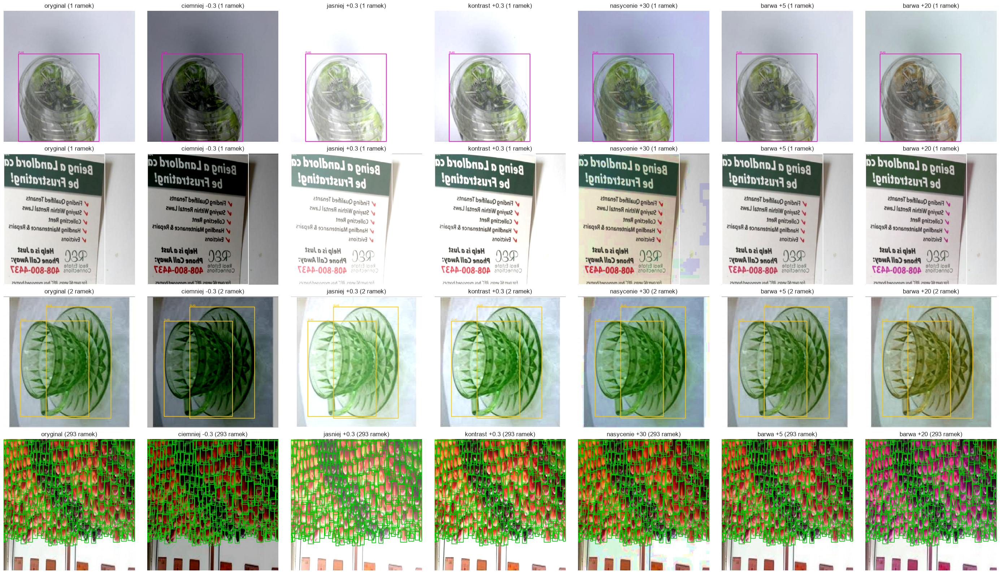

In [21]:
colors = {
    "ciemniej -0.3": compose(A.RandomBrightnessContrast(brightness_limit=(-0.3, -0.3), contrast_limit=0, p=1)),
    "jasniej +0.3": compose(A.RandomBrightnessContrast(brightness_limit=(0.3, 0.3), contrast_limit=0, p=1)),
    "kontrast +0.3": compose(A.RandomBrightnessContrast(brightness_limit=0, contrast_limit=(0.3, 0.3), p=1)),
    "nasycenie +30": compose(A.HueSaturationValue(hue_shift_limit=0, sat_shift_limit=(30, 30), val_shift_limit=0, p=1)),
    "barwa +5": compose(A.HueSaturationValue(hue_shift_limit=(5, 5), sat_shift_limit=0, val_shift_limit=0, p=1)),
    "barwa +20": compose(
        A.HueSaturationValue(hue_shift_limit=(20, 20), sat_shift_limit=0, val_shift_limit=0, p=1)), #za duzo - zmienia kolor obiektu np. zielone szklo na niebieskie
}
show(SAMPLES, colors, "03_kolory.png")

Docelowy zestaw augmentacji

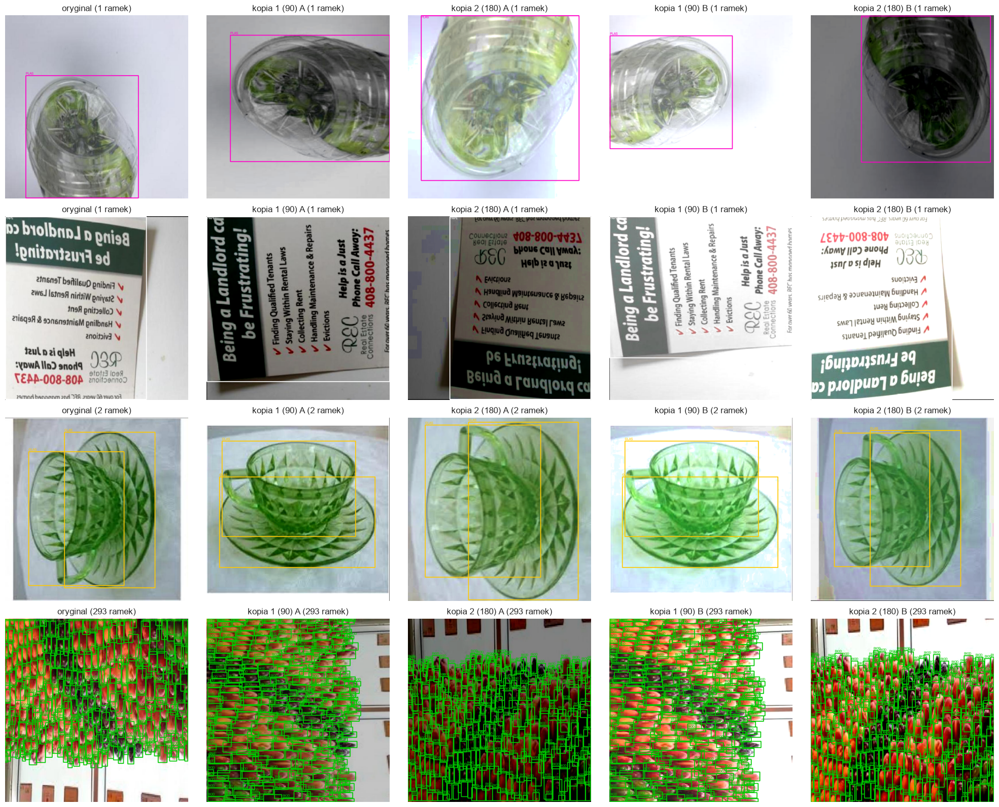

In [22]:
ROTATE_90 = True
ROTATIONS = [[A.Transpose(p=1), A.HorizontalFlip(p=1)], [A.HorizontalFlip(p=1), A.VerticalFlip(p=1)]] #90 i 180 stopni

def strong_copy(k):
    rotate = ROTATIONS[k % len(ROTATIONS)] if ROTATE_90 else [] #kopia 1 -> 90, kopia 2 -> 180 zeby sie roznily
    return A.Compose(rotate + [
        A.HorizontalFlip(p=0.5),                                                                #50%
        A.RandomSizedBBoxSafeCrop(height=640, width=640, p=0.5),                                #przyblizenie bez ucinania ramek
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.9),            #inne oswietlenie
        A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=30, val_shift_limit=0, p=0.5),  #barwa tylko +-5 zeby nie zmienic koloru
    ], bbox_params=BBOX, seed=SEED + 1 + k) #inny seed dla kazdej kopii

STRONG = [strong_copy(k) for k in range(MAX_COPIES)]

#A i B - to samo ustawienie drugi raz, losowanie daje inny wynik
show(SAMPLES, {"kopia 1 (90) A": STRONG[0], "kopia 2 (180) A": STRONG[1], "kopia 1 (90) B": STRONG[0], "kopia 2 (180) B": STRONG[1]}, "04_zestawy.png")

Przyklady - klasy PLASTIC i PAPER

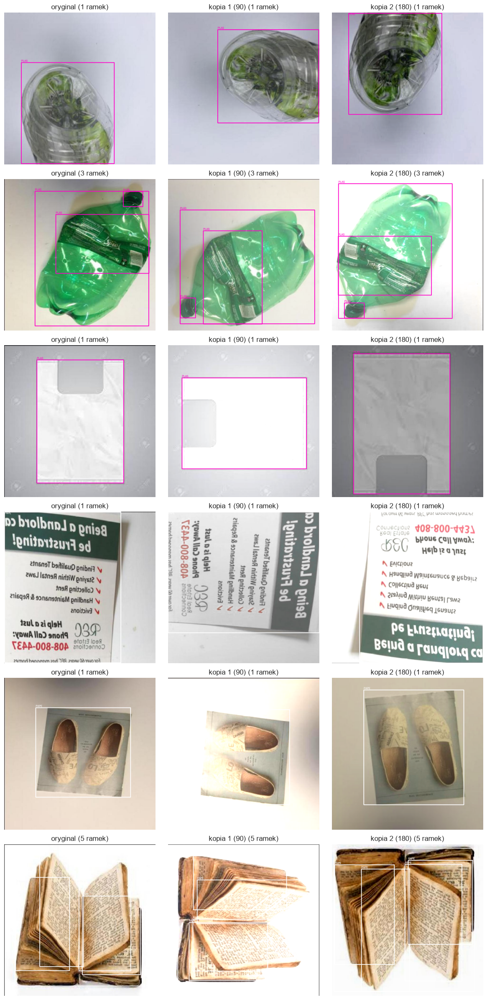

In [23]:
show(pick("PLASTIC", 3) + pick("PAPER", 3), {"kopia 1 (90)": STRONG[0], "kopia 2 (180)": STRONG[1]}, "05_slabe_klasy.png")

Wplyw augmentacji na rozmiar ramek

In [24]:
def box_areas(transform, n=300):
    before, after = [], []
    for path in train_df.sample(n, random_state=SEED)["image"]:
        image, bboxes, classes = load(path)
        out = transform(image=image, bboxes=bboxes, classes=classes)
        before += list(bboxes[:, 2] * bboxes[:, 3]) #pole ramki szerokosc x wysokosc
        after += [w * h for x, y, w, h in out["bboxes"]]
    return np.array(before), np.array(after)


summary = []
for title, t in {"kopia 1": STRONG[0], "kopia 2": STRONG[1], "oddalenie x0.7": scales["oddalenie x0.7"],
                 "przyblizenie x1.3": scales["przyblizenie x1.3"]}.items():
    before, after = box_areas(t)
    summary.append({"augmentacja": title, "ramek przed": len(before), "ramek po": len(after),
                    "zgubione ramki %": round((1 - len(after) / len(before)) * 100, 1),
                    "mediana pola przed %": round(np.median(before) * 100, 2),
                    "mediana pola po %": round(np.median(after) * 100, 2),
                    "ramki < 0.1% zdjecia po": int((after < 0.001).sum())}) #za male - model nie widzi
pd.DataFrame(summary)

,augmentacja,ramek przed,ramek po,zgubione ramki %,mediana pola przed %,mediana pola po %,ramki < 0.1% zdjecia po
0,kopia 1,1986,1986,0.0,1.65,1.74,99
1,kopia 2,1986,1986,0.0,1.65,1.72,99
2,oddalenie x0.7,1986,1986,0.0,1.65,0.81,341
3,przyblizenie x1.3,1986,1706,14.1,1.65,2.96,60
